# Tugas Praktikum 5: Sequential Pattern

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)

### 1. Import Dataset

In [2]:
df = pd.read_excel('Online Retail.xlsx')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Shape dataset:", df.shape)

df.info()

Shape dataset: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### 2. Eksplorasi dan Pembersihan Data

In [ ]:
df[['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Description']].head()

,CustomerID,InvoiceNo,InvoiceDate,Description
0,17850.0,536365,2010-12-01 08:26:00,WHITE HANGING HEART T-LIGHT HOLDER
1,17850.0,536365,2010-12-01 08:26:00,WHITE METAL LANTERN
2,17850.0,536365,2010-12-01 08:26:00,CREAM CUPID HEARTS COAT HANGER
3,17850.0,536365,2010-12-01 08:26:00,KNITTED UNION FLAG HOT WATER BOTTLE
4,17850.0,536365,2010-12-01 08:26:00,RED WOOLLY HOTTIE WHITE HEART.


In [5]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

print("Missing values pada dataset:")
print(df.isnull().sum())

print()
print("Description kosong          :", df['Description'].isnull().sum())
print("Transaksi dibatalkan (C...)  :", df['InvoiceNo'].str.startswith('C').sum())
print("Quantity <= 0                :", (df['Quantity'] <= 0).sum())
print("CustomerID kosong            :", df['CustomerID'].isnull().sum())

Missing values pada dataset:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Description kosong          : 1454


Transaksi dibatalkan (C...)  : 9288
Quantity <= 0                : 10624
CustomerID kosong            : 135080


In [6]:
baris_sebelum = df.shape[0]
invoice_sebelum = df['InvoiceNo'].nunique()
pelanggan_sebelum = df['CustomerID'].nunique()

df_clean = df.dropna(subset=['Description'])
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean = df_clean.dropna(subset=['CustomerID']).copy()

df_clean['Description'] = df_clean['Description'].str.strip()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

baris_sesudah = df_clean.shape[0]
invoice_sesudah = df_clean['InvoiceNo'].nunique()
pelanggan_sesudah = df_clean['CustomerID'].nunique()

perbandingan = pd.DataFrame({
    'Sebelum': [baris_sebelum, invoice_sebelum, pelanggan_sebelum],
    'Sesudah': [baris_sesudah, invoice_sesudah, pelanggan_sesudah],
}, index=['Jumlah Baris', 'Jumlah Invoice', 'Jumlah Pelanggan'])
perbandingan['Terhapus'] = perbandingan['Sebelum'] - perbandingan['Sesudah']

display(perbandingan)
print("Jumlah produk unik setelah pembersihan:", df_clean['Description'].nunique())

,Sebelum,Sesudah,Terhapus
Jumlah Baris,541909,397924,143985
Jumlah Invoice,25900,18536,7364
Jumlah Pelanggan,4372,4339,33


Jumlah produk unik setelah pembersihan: 3866


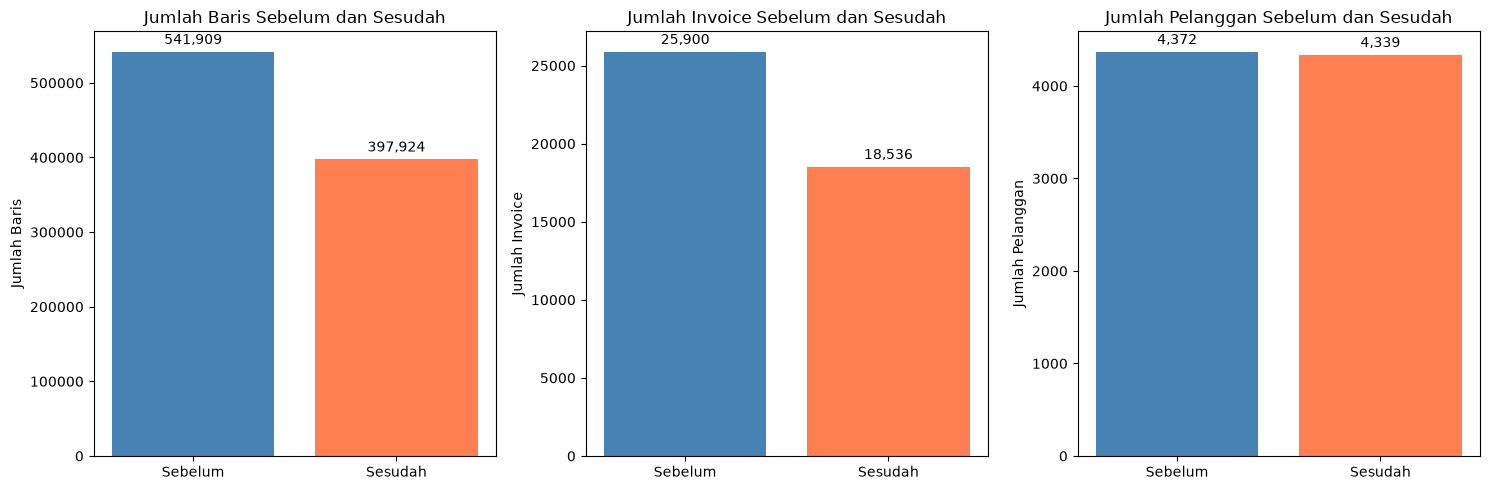

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, kolom in zip(axes, perbandingan.index):
    bars = ax.bar(['Sebelum', 'Sesudah'], perbandingan.loc[kolom, ['Sebelum', 'Sesudah']],
                  color=['steelblue', 'coral'])
    ax.bar_label(bars, fmt='{:,.0f}', padding=3)
    ax.set_title(f'{kolom} Sebelum dan Sesudah')
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.show()

count    4339.00
mean        4.27
std         7.71
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       210.00
Name: InvoiceNo, dtype: float64

Pelanggan dengan 1 invoice   : 1494
Pelanggan dengan >= 2 invoice: 2845


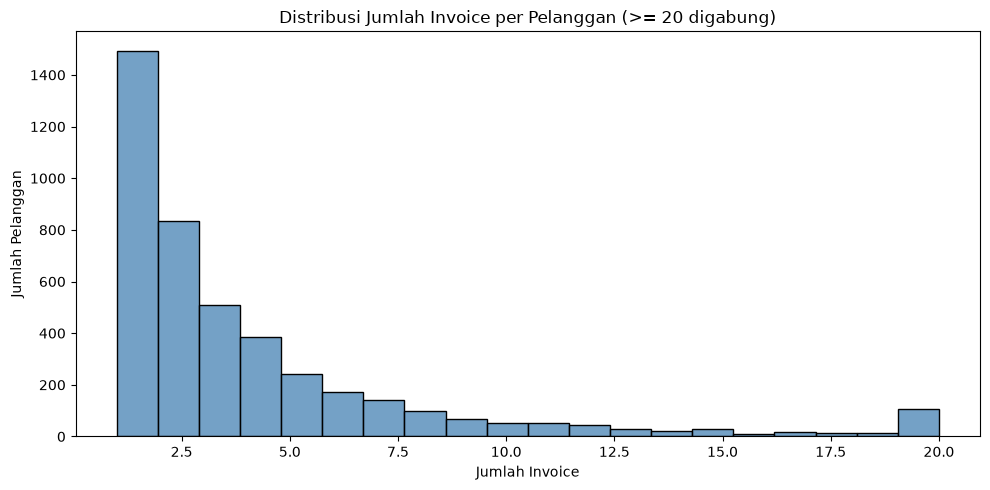

In [8]:
invoice_per_pelanggan = df_clean.groupby('CustomerID')['InvoiceNo'].nunique()

print(invoice_per_pelanggan.describe().round(2))
print()
print("Pelanggan dengan 1 invoice   :", (invoice_per_pelanggan == 1).sum())
print("Pelanggan dengan >= 2 invoice:", (invoice_per_pelanggan >= 2).sum())

plt.figure(figsize=(10, 5))
sns.histplot(invoice_per_pelanggan.clip(upper=20), bins=20, color='steelblue')
plt.title('Distribusi Jumlah Invoice per Pelanggan (>= 20 digabung)')
plt.xlabel('Jumlah Invoice')
plt.ylabel('Jumlah Pelanggan')
plt.tight_layout()
plt.show()

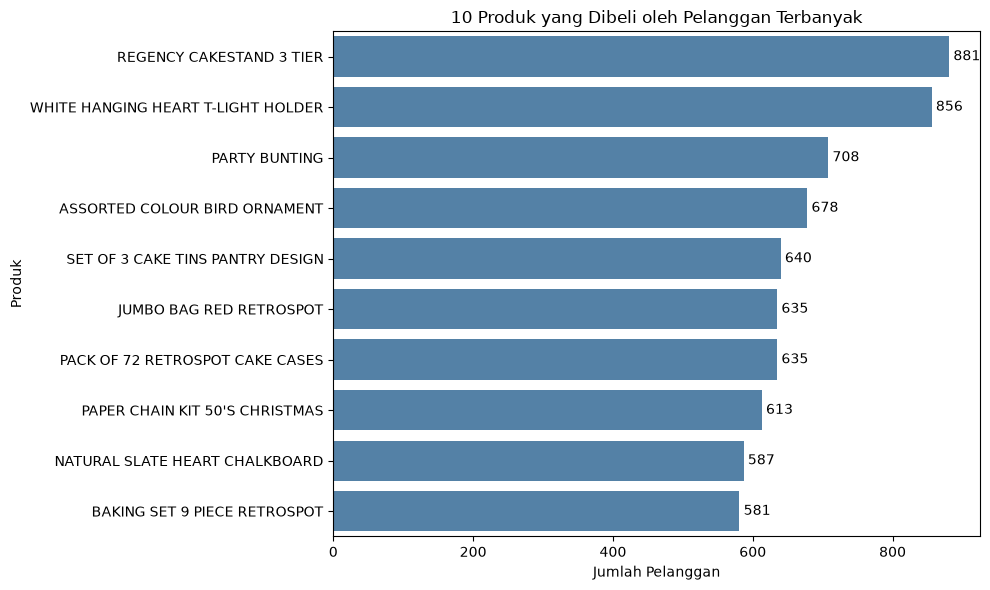

In [9]:
top_produk = df_clean.groupby('Description')['CustomerID'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_produk.values, y=top_produk.index, color='steelblue')
ax.bar_label(ax.containers[0], padding=3)
plt.title('10 Produk yang Dibeli oleh Pelanggan Terbanyak')
plt.xlabel('Jumlah Pelanggan')
plt.ylabel('Produk')
plt.tight_layout()
plt.show()

### 3. Persiapan Data untuk Sequential Pattern Mining

In [ ]:
df_sorted = df_clean.sort_values(['CustomerID', 'InvoiceDate'])

itemset_invoice = (df_sorted.groupby(['CustomerID', 'InvoiceNo'], sort=False)
                   .agg(InvoiceDate=('InvoiceDate', 'first'),
                        Description=('Description', lambda x: sorted(set(x))))
                   .reset_index())

print("Jumlah itemset (invoice):", len(itemset_invoice))
itemset_invoice.head()

Jumlah itemset (invoice): 18536


,CustomerID,InvoiceNo,InvoiceDate,Description
0,12346,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE..."
2,12347,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE..."
3,12347,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE JET SET RED, AIRLINE BAG VINTAGE JET S..."
4,12347,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE TOKYO 78, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELI..."


In [ ]:
print("Jumlah invoice setelah pembersihan:", invoice_sesudah)
print("Jumlah itemset yang terbentuk      :", len(itemset_invoice))
print("Invoice dengan CustomerID dan timestamp yang sama (tetap dipisah):",
      itemset_invoice.duplicated(['CustomerID', 'InvoiceDate'], keep=False).sum())
print("Ada produk dobel dalam satu itemset:",
      itemset_invoice['Description'].apply(lambda x: len(x) != len(set(x))).any())

Jumlah invoice setelah pembersihan: 18536
Jumlah itemset yang terbentuk      : 18536
Invoice dengan CustomerID dan timestamp yang sama (tetap dipisah): 244
Ada produk dobel dalam satu itemset: False


In [ ]:
sequence_pelanggan = itemset_invoice.groupby('CustomerID', sort=False)['Description'].apply(list)
sequences = sequence_pelanggan.tolist()
n_pelanggan = len(sequences)

print("Jumlah sequence (pelanggan):", n_pelanggan)
print()
print("Contoh sequence pelanggan", sequence_pelanggan.index[1], ":")
for i, itemset in enumerate(sequences[1][:3]):
    print(f"  Itemset {i+1}: {itemset[:5]} ... ({len(itemset)} item)")

Jumlah sequence (pelanggan): 4339

Contoh sequence pelanggan 12347 :
  Itemset 1: ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN', 'ALARM CLOCK BAKELIKE ORANGE'] ... (31 item)
  Itemset 2: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET WHITE'] ... (29 item)
  Itemset 3: ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET RED', 'AIRLINE BAG VINTAGE JET SET WHITE'] ... (24 item)


In [13]:
panjang_sequence = pd.Series([len(s) for s in sequences])
print("Statistik panjang sequence (jumlah itemset per pelanggan):")
print(panjang_sequence.describe().round(2))

Statistik panjang sequence (jumlah itemset per pelanggan):
count    4339.00
mean        4.27
std         7.71
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       210.00
dtype: float64


In [ ]:
def prefixspan(db, min_count):
    hasil = []

    hitung_produk = {}
    for seq in db:
        for item in set().union(*seq):
            hitung_produk[item] = hitung_produk.get(item, 0) + 1
    produk_frequent = {item for item, count in hitung_produk.items() if count >= min_count}
    db = [[itemset & produk_frequent for itemset in seq] for seq in db]

    def mine(prefix, projected):
        hitung_i = {}
        hitung_s = {}
        for sid, posisi in projected.items():
            seq = db[sid]

            if prefix:
                item_terakhir = prefix[-1][-1]
                kandidat_i = set()
                for p in posisi:
                    kandidat_i.update(item for item in seq[p] if item > item_terakhir)
                for item in kandidat_i:
                    hitung_i[item] = hitung_i.get(item, 0) + 1

            kandidat_s = set()
            for itemset in seq[posisi[0] + 1:]:
                kandidat_s.update(itemset)
            for item in kandidat_s:
                hitung_s[item] = hitung_s.get(item, 0) + 1

        for item, count in hitung_i.items():
            if count >= min_count:
                pola = prefix[:-1] + [prefix[-1] + (item,)]
                projected_baru = {}
                for sid, posisi in projected.items():
                    cocok = [p for p in posisi if item in db[sid][p]]
                    if cocok:
                        projected_baru[sid] = cocok
                hasil.append((pola, count))
                mine(pola, projected_baru)

        for item, count in hitung_s.items():
            if count >= min_count:
                pola = prefix + [(item,)]
                projected_baru = {}
                for sid, posisi in projected.items():
                    seq = db[sid]
                    cocok = [j for j in range(posisi[0] + 1, len(seq)) if item in seq[j]]
                    if cocok:
                        projected_baru[sid] = cocok
                hasil.append((pola, count))
                mine(pola, projected_baru)

    mine([], {sid: [-1] for sid in range(len(db))})
    return hasil

In [ ]:
def format_pola(pola):
    return ' -> '.join('{' + ', '.join(itemset) + '}' for itemset in pola)


def jenis_pola(pola):
    if len(pola) >= 2:
        return 'pembelian berurutan'
    if len(pola[0]) >= 2:
        return 'pembelian bersamaan'
    return 'satu produk'


def buat_tabel_pola(hasil, n):
    tabel = pd.DataFrame(hasil, columns=['pattern', 'count'])
    tabel['support'] = tabel['count'] / n
    tabel['n_itemset'] = tabel['pattern'].apply(len)
    tabel['n_item'] = tabel['pattern'].apply(lambda p: sum(len(itemset) for itemset in p))
    tabel['jenis'] = tabel['pattern'].apply(jenis_pola)
    tabel['sequence'] = tabel['pattern'].apply(format_pola)

    support_pola = {tuple(p): s for p, s in zip(tabel['pattern'], tabel['support'])}
    tabel['prefix'] = tabel['pattern'].apply(lambda p: format_pola(p[:-1]) if len(p) >= 2 else '')
    tabel['itemset_akhir'] = tabel['pattern'].apply(lambda p: format_pola(p[-1:]) if len(p) >= 2 else '')
    tabel['confidence'] = [s / support_pola[tuple(p[:-1])] if len(p) >= 2 else np.nan
                           for p, s in zip(tabel['pattern'], tabel['support'])]
    return tabel


def mengandung_pola(seq, pola):
    pos = 0
    for itemset in pola:
        while pos < len(seq) and not set(itemset) <= seq[pos]:
            pos += 1
        if pos == len(seq):
            return False
        pos += 1
    return True

In [ ]:
db = [[set(itemset) for itemset in seq] for seq in sequences]

min_support_awal = 0.01
min_count_awal = int(np.ceil(min_support_awal * n_pelanggan))

start = time.time()
hasil_awal = prefixspan(db, min_count_awal)
print(f"Waktu eksekusi: {time.time() - start:.1f} detik")

pola_awal = buat_tabel_pola(hasil_awal, n_pelanggan)

print("Min count (pelanggan):", min_count_awal)
print("Jumlah pola          :", len(pola_awal))
print()
print(pola_awal['jenis'].value_counts())

Waktu eksekusi: 307.2 detik


Min count (pelanggan): 44
Jumlah pola          : 142353

jenis
pembelian berurutan    131356
pembelian bersamaan      9234
satu produk              1763
Name: count, dtype: int64


In [20]:
hasil = []
for s in [0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04]:
    p = pola_awal[pola_awal['count'] >= np.ceil(s * n_pelanggan)]
    hasil.append({'min_support': s,
                  'jumlah_pola': len(p),
                  'satu_produk': (p['jenis'] == 'satu produk').sum(),
                  'pembelian_bersamaan': (p['jenis'] == 'pembelian bersamaan').sum(),
                  'pembelian_berurutan': (p['jenis'] == 'pembelian berurutan').sum(),
                  'itemset_maks': p['n_itemset'].max()})

hasil_support = pd.DataFrame(hasil)
display(hasil_support)

,min_support,jumlah_pola,satu_produk,pembelian_bersamaan,pembelian_berurutan,itemset_maks
0,0.010,142353,1763,9234,131356,7
1,0.015,16700,1350,2712,12638,5
2,0.020,5176,1046,1154,2976,4
3,0.025,2233,824,515,894,4
4,0.030,1259,657,269,333,4
5,0.035,822,532,154,136,3
6,0.040,567,422,89,56,3


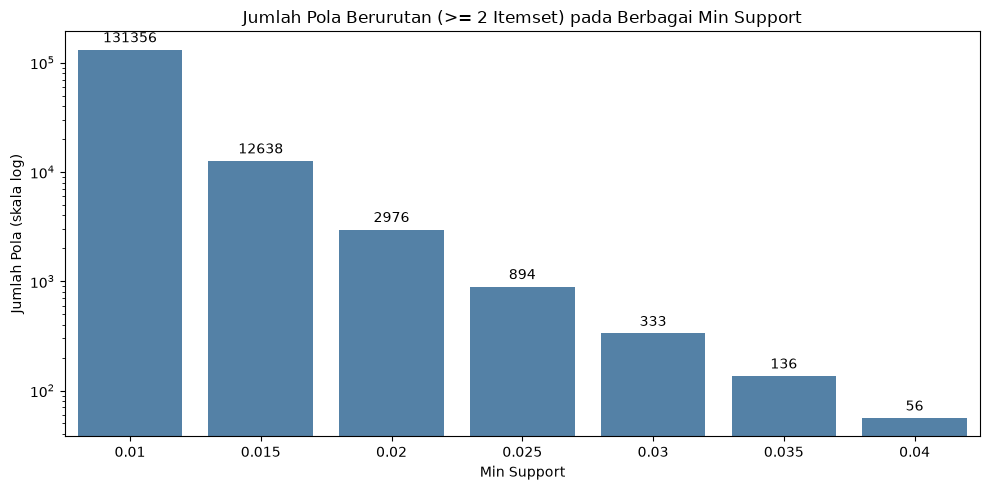

In [21]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=hasil_support, x='min_support', y='pembelian_berurutan', color='steelblue')
ax.bar_label(ax.containers[0], padding=3)
plt.yscale('log')
plt.title('Jumlah Pola Berurutan (>= 2 Itemset) pada Berbagai Min Support')
plt.xlabel('Min Support')
plt.ylabel('Jumlah Pola (skala log)')
plt.tight_layout()
plt.show()

In [ ]:
min_support = 0.03
min_count = int(np.ceil(min_support * n_pelanggan))

pola = pola_awal[pola_awal['count'] >= min_count].reset_index(drop=True)

hasil_ulang = prefixspan(db, min_count)
print("Hasil filter = hasil PrefixSpan ulang:",
      set(pola['sequence']) == {format_pola(p) for p, c in hasil_ulang})
print()
print("Min count (pelanggan):", min_count)
print("Jumlah pola          :", len(pola))
print()
print(pola['jenis'].value_counts())
print()
print("Jumlah itemset per pola:")
print(pola['n_itemset'].value_counts().sort_index())

Hasil filter = hasil PrefixSpan ulang: True

Min count (pelanggan): 131
Jumlah pola          : 1259

jenis
satu produk            657
pembelian berurutan    333
pembelian bersamaan    269
Name: count, dtype: int64

Jumlah itemset per pola:
n_itemset
1    926
2    323
3      9
4      1
Name: count, dtype: int64


In [ ]:
start = time.time()
support_langsung = pola['pattern'].apply(lambda p: sum(mengandung_pola(seq, p) for seq in db))
print(f"Waktu pengecekan: {time.time() - start:.1f} detik")
print("Jumlah pola yang dicek                     :", len(pola))
print("Support PrefixSpan = support pengecekan langsung:", (support_langsung == pola['count']).all())

Waktu pengecekan: 3.5 detik
Jumlah pola yang dicek                     : 1259
Support PrefixSpan = support pengecekan langsung: True


### 5. Evaluasi Pola Berurutan

In [24]:
pola_tampil = pola.sort_values(['support', 'confidence'], ascending=False).reset_index(drop=True)
kolom_tampil = ['sequence', 'jenis', 'n_itemset', 'n_item', 'count', 'support', 'confidence']

display(pola_tampil[kolom_tampil].round(4))

,sequence,jenis,n_itemset,n_item,count,support,confidence
0,{REGENCY CAKESTAND 3 TIER},satu produk,1,1,881,0.2030,NaN
1,{WHITE HANGING HEART T-LIGHT HOLDER},satu produk,1,1,856,0.1973,NaN
2,{PARTY BUNTING},satu produk,1,1,708,0.1632,NaN
3,{ASSORTED COLOUR BIRD ORNAMENT},satu produk,1,1,678,0.1563,NaN
4,{SET OF 3 CAKE TINS PANTRY DESIGN},satu produk,1,1,640,0.1475,NaN
...,...,...,...,...,...,...,...
1254,"{LUNCH BAG CARS BLUE, LUNCH BAG RED RETROSPOT, LUNCH BAG WOODLAND}",pembelian bersamaan,1,3,131,0.0302,NaN
1255,"{LUNCH BAG SUKI DESIGN, LUNCH BAG VINTAGE DOILY}",pembelian bersamaan,1,2,131,0.0302,NaN
1256,"{JUMBO BAG DOILEY PATTERNS, JUMBO BAG VINTAGE LEAF}",pembelian bersamaan,1,2,131,0.0302,NaN
1257,{HEART WOODEN CHRISTMAS DECORATION},satu produk,1,1,131,0.0302,NaN


In [ ]:
pola_berurutan = pola_tampil[pola_tampil['jenis'] == 'pembelian berurutan'].reset_index(drop=True)

display(pola_berurutan[['sequence', 'prefix', 'itemset_akhir', 'count', 'support', 'confidence']].round(4))

,sequence,prefix,itemset_akhir,count,support,confidence
0,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},{WHITE HANGING HEART T-LIGHT HOLDER},{WHITE HANGING HEART T-LIGHT HOLDER},405,0.0933,0.4731
1,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},{REGENCY CAKESTAND 3 TIER},{REGENCY CAKESTAND 3 TIER},330,0.0761,0.3746
2,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},{JUMBO BAG RED RETROSPOT},{JUMBO BAG RED RETROSPOT},312,0.0719,0.4913
3,{ASSORTED COLOUR BIRD ORNAMENT} -> {ASSORTED COLOUR BIRD ORNAMENT},{ASSORTED COLOUR BIRD ORNAMENT},{ASSORTED COLOUR BIRD ORNAMENT},291,0.0671,0.4292
4,{PARTY BUNTING} -> {PARTY BUNTING},{PARTY BUNTING},{PARTY BUNTING},280,0.0645,0.3955
...,...,...,...,...,...,...
328,{JAM MAKING SET WITH JARS} -> {SET OF 3 CAKE TINS PANTRY DESIGN},{JAM MAKING SET WITH JARS},{SET OF 3 CAKE TINS PANTRY DESIGN},131,0.0302,0.2286
329,{PACK OF 72 RETROSPOT CAKE CASES} -> {REGENCY CAKESTAND 3 TIER},{PACK OF 72 RETROSPOT CAKE CASES},{REGENCY CAKESTAND 3 TIER},131,0.0302,0.2063
330,{JUMBO BAG RED RETROSPOT} -> {LUNCH BAG ALPHABET DESIGN},{JUMBO BAG RED RETROSPOT},{LUNCH BAG ALPHABET DESIGN},131,0.0302,0.2063
331,{SET OF 3 CAKE TINS PANTRY DESIGN} -> {JUMBO BAG RED RETROSPOT},{SET OF 3 CAKE TINS PANTRY DESIGN},{JUMBO BAG RED RETROSPOT},131,0.0302,0.2047


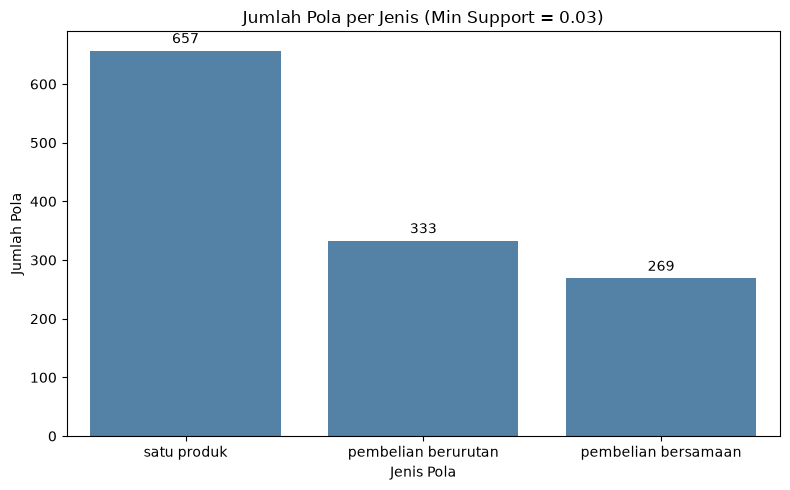

In [26]:
jumlah_jenis = pola_tampil['jenis'].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=jumlah_jenis.index, y=jumlah_jenis.values, color='steelblue')
ax.bar_label(ax.containers[0], padding=3)
plt.title(f'Jumlah Pola per Jenis (Min Support = {min_support})')
plt.xlabel('Jenis Pola')
plt.ylabel('Jumlah Pola')
plt.tight_layout()
plt.show()

In [27]:
pola_berurutan[['support', 'confidence']].describe().round(4)

,support,confidence
count,333.0000,333.0000
mean,0.0361,0.3478
std,0.0070,0.1162
min,0.0302,0.1487
25%,0.0318,0.2500
50%,0.0341,0.3507
75%,0.0383,0.4220
max,0.0933,0.6700


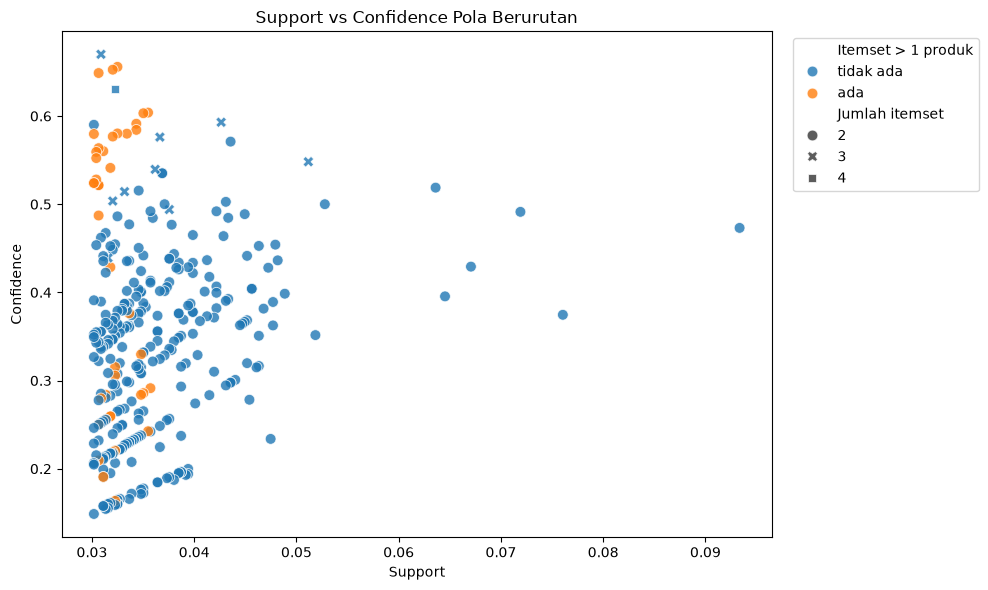

In [28]:
pola_berurutan['itemset_multi_produk'] = pola_berurutan['pattern'].apply(
    lambda p: 'ada' if any(len(itemset) > 1 for itemset in p) else 'tidak ada')

data_plot = pola_berurutan.rename(columns={'itemset_multi_produk': 'Itemset > 1 produk',
                                           'n_itemset': 'Jumlah itemset'})

plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_plot, x='support', y='confidence', hue='Itemset > 1 produk',
                style='Jumlah itemset', s=60, alpha=0.8)
plt.title('Support vs Confidence Pola Berurutan')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

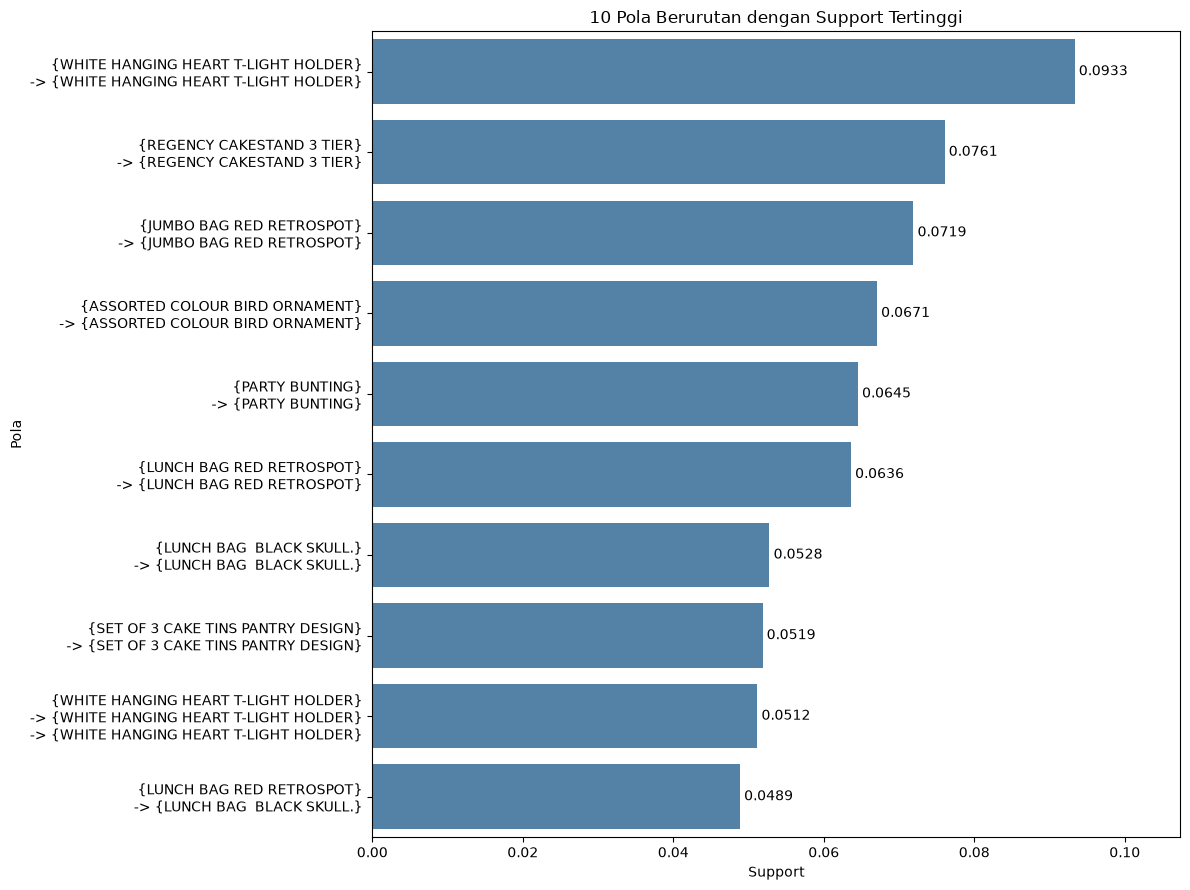

In [29]:
top10 = pola_berurutan.head(10)
label = top10['sequence'].str.replace(' -> ', '\n-> ', regex=False)

plt.figure(figsize=(12, 9))
ax = sns.barplot(x=top10['support'].values, y=label.values, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.4f', padding=3)
plt.title('10 Pola Berurutan dengan Support Tertinggi')
plt.xlabel('Support')
plt.ylabel('Pola')
plt.xlim(0, top10['support'].max() * 1.15)
plt.tight_layout()
plt.show()

#### Tiga Pola Terbaik (Support Tertinggi)

In [ ]:
top3 = pola_tampil.head(3)
display(top3[kolom_tampil].round(4))

,sequence,jenis,n_itemset,n_item,count,support,confidence
0,{REGENCY CAKESTAND 3 TIER},satu produk,1,1,881,0.2030,NaN
1,{WHITE HANGING HEART T-LIGHT HOLDER},satu produk,1,1,856,0.1973,NaN
2,{PARTY BUNTING},satu produk,1,1,708,0.1632,NaN


In [ ]:
pola_bersamaan = pola_tampil[pola_tampil['jenis'] == 'pembelian bersamaan']
print("Pembelian bersamaan dengan support tertinggi:")
display(pola_bersamaan[['sequence', 'n_item', 'count', 'support']].head(5).round(4))

pola_beda = pola_berurutan[pola_berurutan['pattern'].apply(lambda p: len({i for s in p for i in s}) > 1)]
print("Jumlah pola berurutan berupa pembelian ulang produk yang sama:", len(pola_berurutan) - len(pola_beda))
print("Jumlah pola berurutan dengan produk berbeda                 :", len(pola_beda))
print()
print("Pembelian berurutan dengan produk berbeda:")
display(pola_beda[['sequence', 'count', 'support', 'confidence']].head(5).round(4))

pola_campuran = pola_berurutan[pola_berurutan['itemset_multi_produk'] == 'ada']
print("Jumlah pola berurutan yang memuat itemset > 1 produk:", len(pola_campuran))
display(pola_campuran[['sequence', 'count', 'support', 'confidence']].head(5).round(4))

Pembelian bersamaan dengan support tertinggi:


,sequence,n_item,count,support
111,"{PAPER CHAIN KIT 50'S CHRISTMAS, PAPER CHAIN KIT VINTAGE CHRISTMAS}",2,313,0.0721
114,"{GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}",2,311,0.0717
151,"{GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER}",2,282,0.0650
162,"{HEART OF WICKER LARGE, HEART OF WICKER SMALL}",2,276,0.0636
166,"{RED HANGING HEART T-LIGHT HOLDER, WHITE HANGING HEART T-LIGHT HOLDER}",2,273,0.0629


Jumlah pola berurutan berupa pembelian ulang produk yang sama: 66
Jumlah pola berurutan dengan produk berbeda                 : 267

Pembelian berurutan dengan produk berbeda:


,sequence,count,support,confidence
9,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.0489,0.3985
10,{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT},209,0.0482,0.4363
11,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT},208,0.0479,0.4541
12,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG SPACEBOY DESIGN},207,0.0477,0.3891
14,{REGENCY CAKESTAND 3 TIER} -> {SET OF 3 REGENCY CAKE TINS},206,0.0475,0.2338


Jumlah pola berurutan yang memuat itemset > 1 produk: 42


,sequence,count,support,confidence
122,"{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT, LUNCH BAG SUKI DESIGN}",155,0.0357,0.2914
124,"{LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT}",154,0.0355,0.6039
125,"{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROSPOT}",154,0.0355,0.2425
127,"{LUNCH BAG BLACK SKULL., LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT}",152,0.0350,0.6032
132,"{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT}",152,0.0350,0.2857
